Simple and multiple linear regression: Building models, checking assumptions and evaluating using R² and RMSE

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [1]:
from google.colab import files
import pandas as pd
#upload dataset
uploaded= files.upload()


Saving housing_clean.csv to housing_clean.csv


In [5]:
#read csv file
df = pd.read_csv('housing_clean.csv')
df.head()


,Area,Rooms,Age,Location_Score,Price
0,778,1,6,3,5081030
1,2148,4,27,8,11863210
2,1909,3,3,5,11371453
3,1478,3,16,3,9079771
4,1466,3,14,4,7502204


In [12]:
# 1. Simple Linear Regression (Predicting 'Price' using 'Area')
X_s = df[['Area']]
y = df['Price']
X_tr, X_te, y_tr, y_te = train_test_split(X_s, y, test_size=0.2, random_state=42)

simple_model = LinearRegression().fit(X_tr, y_tr)
y_pred_s = simple_model.predict(X_te)

# Evaluate
print("SIMPLE REGRESSION\n")
print(f"R2: {r2_score(y_te, y_pred_s):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_te, y_pred_s)):.4f}")

SIMPLE REGRESSION

R2: 0.9393
RMSE: 809207.6985


In [16]:
X_m = df[['Area', 'Rooms', 'Age', 'Location_Score']]
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    X_m, y, test_size=0.2, random_state=42
    )

multi_model = LinearRegression().fit(X_tr2, y_tr2)
pred_multi = multi_model.predict(X_te2)

# Evaluate
print("MULTIPLE REGRESSION\n")
print(f"R2: {r2_score(y_te2, y_pred_m):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_te2, y_pred_m)):.4f}")

MULTIPLE REGRESSION

R2: 0.9773
RMSE: 495063.1917


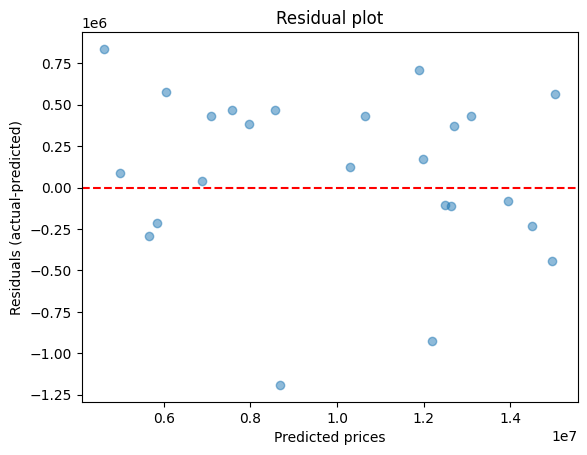

In [18]:
residuals = y_te2 - pred_multi
plt.scatter(pred_multi, residuals, alpha=0.5)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Predicted prices')
plt.ylabel('Residuals (actual-predicted)')
plt.title('Residual plot')
plt.show()